In [1]:
# Imports
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np
import plotly.graph_objects as go       

Se diferencia de `analysis_aco.ipynb` solo en la parte de tweak de hyper-parametros. Como demora mucho en correr lo dividi en dos notebooks

In [2]:
# Plots settings
SOLVER='ACO_v2'
SOLVER_COLORS = {
    SOLVER:             "#ff7f0e",  
}

BLUE_PALETTE = [
    "#d0e4f7",  # very light
    "#a8cce8",  # light
    "#7ab4d9",  # medium-light
    "#4682b4",  # steelblue
    "#2e5f8a",  # medium-dark
    "#1a3d61",  # dark
]

SOLVER_LABELS = {
    SOLVER:             "Aco",
}

SIZE_ORDER = ["small", "medium", "big"]
SIZE_LABELS = {
    "small":  "Pequeño\n(c ≤ 25)",
    "medium": "Mediano\n(25 < c ≤ 50)",
    "big":    "Grande\n(50 < c ≤ 80)",
}

SOLVER_BAR_COLORS = {
    SOLVER:             ["#ff7f0e", "#ffbb78"],  
  }

In [3]:
# import matplotlib.pyplot as plt
# import os

# os.makedirs("figures", exist_ok=True)
# _fig_counter = [0]
# _original_show = plt.show

# def _auto_save_show():
#     _fig_counter[0] += 1
#     plt.savefig(f"/Users/tomasmarmay/Documents/famaf/tesis/src/essay/fig_{_fig_counter[0]:02d}.png", bbox_inches="tight", dpi=150)
#     _original_show()

# plt.show = _auto_save_show

In [3]:
# Load and process data

with open("../../run_results.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = (2*c*v*n) + (3*(n**2)*v) + (2*v*c) + v
    
    df["feasible"] = df["feasible"].map({"t": True, "f": False, True: True, False: False})
    df["valid"] = df["valid"].map({"t": True, "f": False, True: True, False: False})

    return df

df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing4_ACO"))

### 5.2 Análisis individual de ACO

In [4]:
aco = df[df["solver"] == SOLVER].copy()
aco_feasible = aco[aco["feasible"] == True].copy()

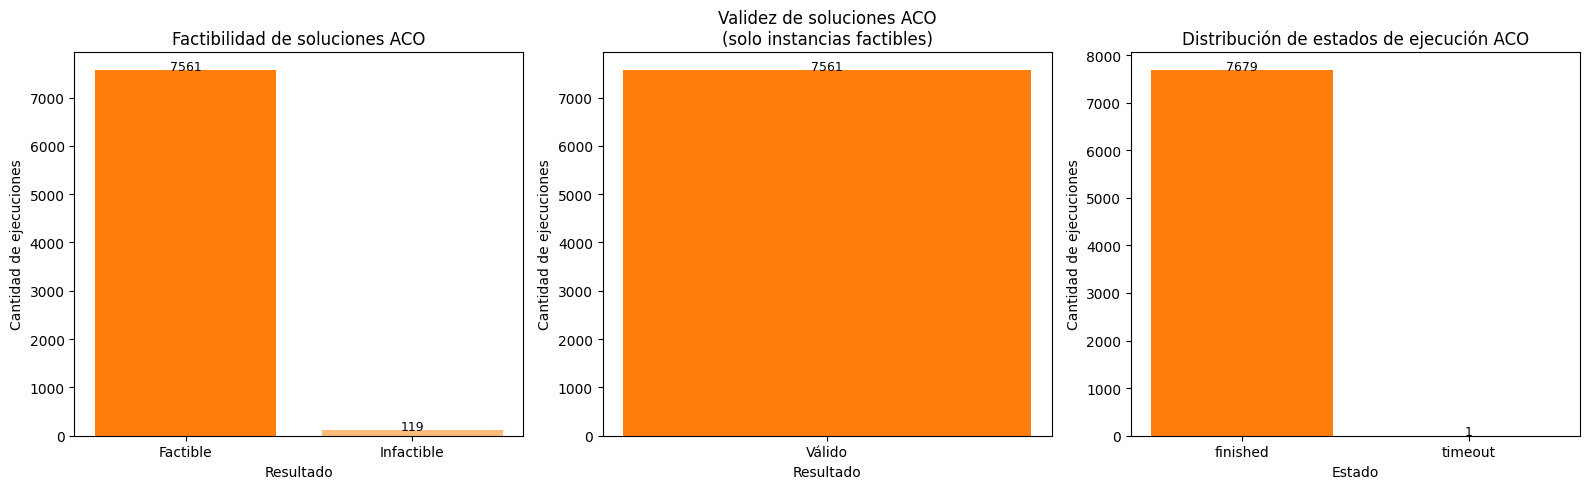

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Feasible / Infeasible ──────────────────────────────────────────────────────
feasible_counts = aco["feasible"].map({True: "Factible", False: "Infactible"}).value_counts()

axes[0].bar(feasible_counts.index, feasible_counts.values, color=SOLVER_BAR_COLORS[SOLVER])
axes[0].set_title("Factibilidad de soluciones ACO")
axes[0].set_xlabel("Resultado")
axes[0].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(feasible_counts.items()):
    axes[0].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Valid / Invalid (solo feasibles) ──────────────────────────────────────────
valid_counts = aco_feasible["valid"].map({True: "Válido", False: "Inválido"}).value_counts()

axes[1].bar(valid_counts.index, valid_counts.values, color=SOLVER_BAR_COLORS[SOLVER])
axes[1].set_title("Validez de soluciones ACO\n(solo instancias factibles)")
axes[1].set_xlabel("Resultado")
axes[1].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(valid_counts.items()):
    axes[1].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Status distribution ────────────────────────────────────────────────────────
status_counts = aco["status"].value_counts()

axes[2].bar(status_counts.index, status_counts.values, color=SOLVER_BAR_COLORS[SOLVER])
axes[2].set_title("Distribución de estados de ejecución ACO")
axes[2].set_xlabel("Estado")
axes[2].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(status_counts.items()):
    axes[2].text(i, val + 5, str(val), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [6]:
def n(mask): return aco[mask].shape[0]                                                                                                                                                
                                                                                                                                                                                    
total               = aco.shape[0]                                                                                                                                                    
n_finished          = n(aco["status"] == "finished")                                                                                                                                  
n_timeout           = n(aco["status"] == "timeout")                                                                                                                                   
finished_feasible   = n((aco["status"] == "finished") & (aco["feasible"] == True))                                                                                                    
finished_infeasible = n((aco["status"] == "finished") & (aco["feasible"] == False))
feasible_valid      = n((aco["feasible"] == True) & (aco["valid"] == True))                                                                                                           
feasible_invalid    = n((aco["feasible"] == True) & (aco["valid"] == False))
                                                                                                                                                                                    
labels = ["Total", "Finished", "Timeout", "Factible", "Infactible", "Válido", "Inválido"]                                                                                             
source = [0, 0,         1,                1,                  2,        3,              3]                                                                                            
target = [1, 2,         3,                4,                  4,        5,              6]                                                                                            
value  = [n_finished, n_timeout,                                                                                                                                                      
        finished_feasible, finished_infeasible,
        n_timeout,                                                                                                                                                                  
        feasible_valid, feasible_invalid]

pcts = [                                                                                                                                                                              
    100,
    n_finished / total * 100,                                                                                                                                                         
    n_timeout  / total * 100,
    finished_feasible / total * 100,
    (finished_infeasible + n_timeout) / total * 100,
    feasible_valid   / total * 100,                                                                                                                                                   
    feasible_invalid / total * 100,
]                                                                                                                                                                                     
                
x = [0.01, 0.33, 0.33, 0.66, 0.66, 0.99, 0.99]                                                                                                                                        
y = [0.40, 0.10, 0.65, 0.15, 0.70, 0.10, 0.55]
x = [.001 if v == 0 else .999 if v == 1 else v for v in x]                                                                                                                            
y = [.001 if v == 0 else .999 if v == 1 else v for v in y]                                                                                                                            

node_colors = [                                                                                                                                                                       
    BLUE_PALETTE[3],
    BLUE_PALETTE[5], BLUE_PALETTE[2],                                                                                                                                                 
    "#2ecc71", "#e74c3c",
    "#27ae60", "#c0392b",
]                                                                                                                                                                                     

link_colors = [                                                                                                                                                                       
    "rgba(70,130,180,0.3)",
    "rgba(70,130,180,0.3)",
    "rgba(46,204,113,0.3)",
    "rgba(231,76,60,0.3)",                                                                                                                                                            
    "rgba(231,76,60,0.3)",
    "rgba(39,174,96,0.3)",                                                                                                                                                            
    "rgba(192,57,43,0.3)",
]                                                                                                                                                                                     

fig = go.Figure(go.Sankey(                                                                                                                                                            
    textfont=dict(color="black", size=12),
    node=dict(
        pad=35, thickness=20,
        line=dict(color="white", width=1),                                                                                                                                            
        label=[f"{name}<br>{pct:.1f}%" for name, pct in zip(labels, pcts)],
        x=x, y=y,                                                                                                                                                                     
    ),                                                                                                                                                                                
    link=dict(source=source, target=target, value=value, color=link_colors),
))                                                                                                                                                                                    
                
fig.update_layout(
    title="<span style='font-size:22px;color:steelblue;'><b>Flujo de ejecuciones ACO</b></span>",
    font=dict(size=12, color="white"),                                                                                                                                                
    paper_bgcolor="#F8F8FF",
)                                                                                                                                                                                     
fig.update_traces(node_color=node_colors)
fig.show()

/tmp/ipykernel_22287/1563695151.py:18: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



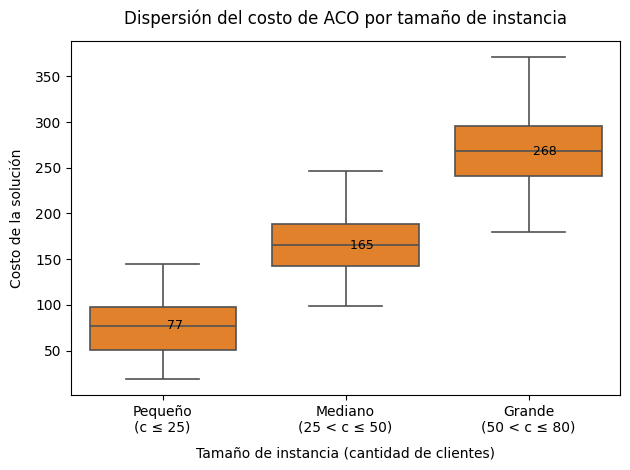

In [7]:
fig, ax = plt.subplots()

sns.boxplot(
    data=aco_feasible,
    x="size",
    y="cost",
    order=SIZE_ORDER,
    color=SOLVER_COLORS[SOLVER],
    linewidth=1.2,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
    ax=ax,
)

# Labels
ax.set_title("Dispersión del costo de ACO por tamaño de instancia", pad=12)
ax.set_xlabel("Tamaño de instancia (cantidad de clientes)", labelpad=8)
ax.set_ylabel("Costo de la solución", labelpad=8)
ax.set_xticklabels([SIZE_LABELS[s] for s in SIZE_ORDER])

# Annotations: median value on top of each box
for i, size in enumerate(SIZE_ORDER):
    subset = aco_feasible[aco_feasible["size"] == size]["cost"]
    if not subset.empty:
        median = subset.median()
        ax.text(i, median, f" {median:.0f}", va="center", ha="left", fontsize=9)

plt.tight_layout()
plt.show()

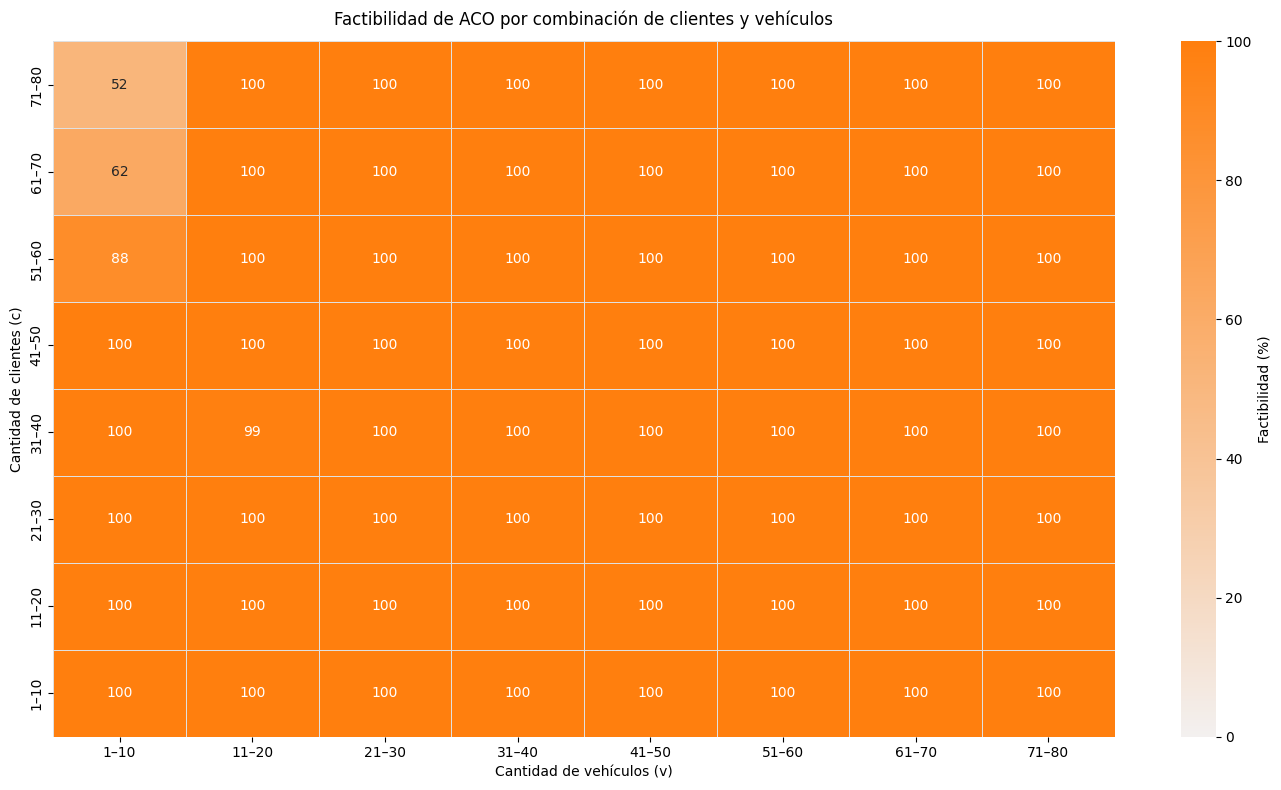

In [8]:
aco["c_bin"] = (((aco["c"] - 1) // 10) * 10 + 1).astype(int).astype(str) + "–" + (((aco["c"] - 1) // 10) * 10 + 10).astype(int).astype(str)
aco["v_bin"] = (((aco["v"] - 1) // 10) * 10 + 1).astype(int).astype(str) + "–" + (((aco["v"] - 1) // 10) * 10 + 10).astype(int).astype(str)

aco["c_mid"] = ((aco["c"] - 1) // 10) * 10 + 1
aco["v_mid"] = ((aco["v"] - 1) // 10) * 10 + 1

feasibility = (
    aco.groupby(["c_mid", "c_bin", "v_mid", "v_bin"])["feasible"]
    .mean()
    .mul(100)
    .round(1)
    .reset_index()
    .pivot(index=["c_mid", "c_bin"], columns=["v_mid", "v_bin"], values="feasible")
    .sort_index(ascending=False)
)

# Use only the label level for display
feasibility.index = feasibility.index.get_level_values("c_bin")
feasibility.columns = feasibility.columns.get_level_values("v_bin")

fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(
    feasibility,
    ax=ax,
    cmap=sns.light_palette(SOLVER_COLORS[SOLVER], as_cmap=True),
    vmin=0,
    vmax=100,
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Factibilidad (%)"},
)

ax.set_title("Factibilidad de ACO por combinación de clientes y vehículos", pad=12)
ax.set_xlabel("Cantidad de vehículos (v)")
ax.set_ylabel("Cantidad de clientes (c)")

plt.tight_layout()
plt.show()

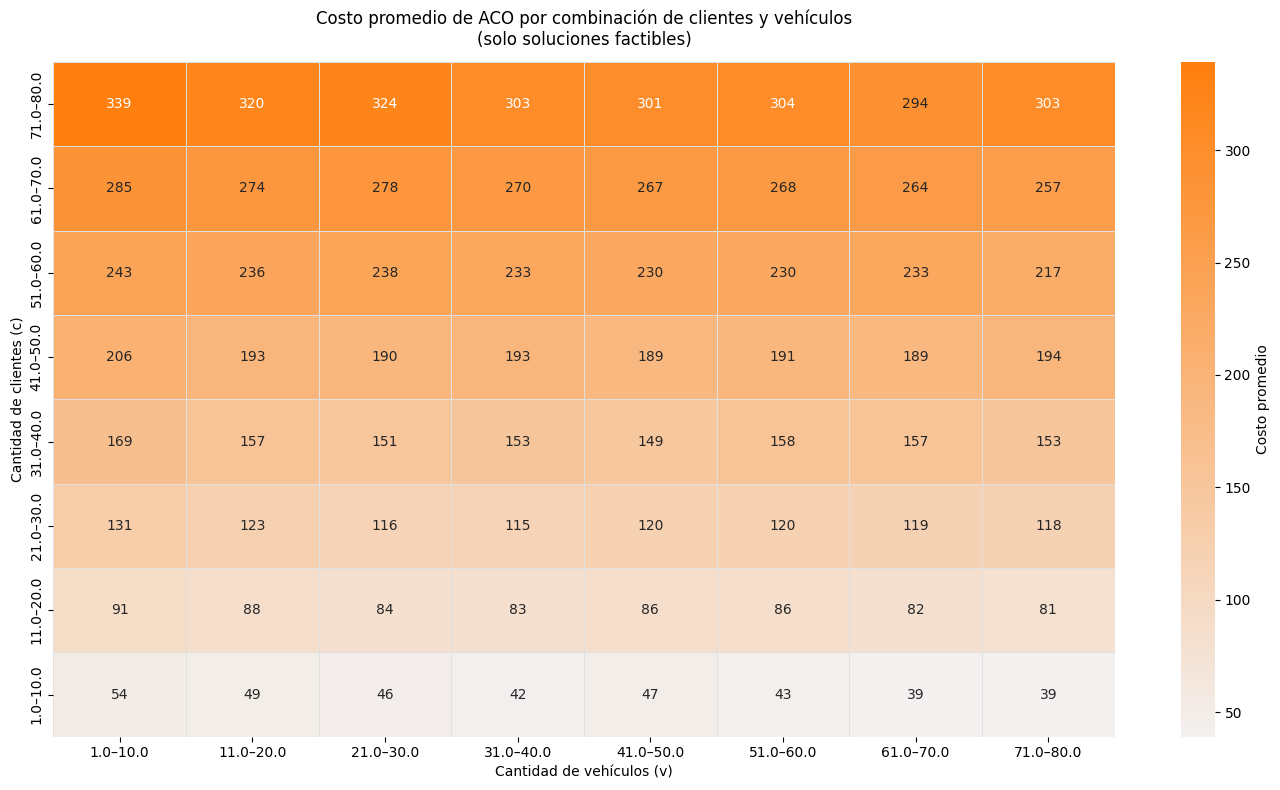

In [11]:
aco_feasible["c_mid"] = ((aco_feasible["c"] - 1) // 10) * 10 + 1
aco_feasible["v_mid"] = ((aco_feasible["v"] - 1) // 10) * 10 + 1
aco_feasible["c_bin"] = aco_feasible["c_mid"].astype(str) + "–" + (aco_feasible["c_mid"] + 9).astype(str)
aco_feasible["v_bin"] = aco_feasible["v_mid"].astype(str) + "–" + (aco_feasible["v_mid"] + 9).astype(str)

cost_pivot = (
    aco_feasible.groupby(["c_mid", "c_bin", "v_mid", "v_bin"])["cost"]
    .mean()
    .round(1)
    .reset_index()
    .pivot(index=["c_mid", "c_bin"], columns=["v_mid", "v_bin"], values="cost")
    .sort_index(ascending=False)
)

cost_pivot.index = cost_pivot.index.get_level_values("c_bin")
cost_pivot.columns = cost_pivot.columns.get_level_values("v_bin")

fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(
    cost_pivot,
    ax=ax,
    cmap=sns.light_palette(SOLVER_COLORS[SOLVER], as_cmap=True),
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Costo promedio"},
)

ax.set_title("Costo promedio de ACO por combinación de clientes y vehículos\n(solo soluciones factibles)", pad=12)
ax.set_xlabel("Cantidad de vehículos (v)")
ax.set_ylabel("Cantidad de clientes (c)")

plt.tight_layout()
plt.show()

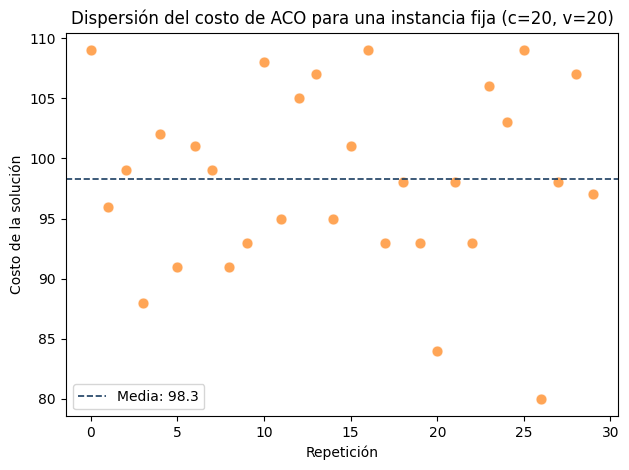

In [10]:
instance = df[
    (df["solver"] == SOLVER) &
    (df["c"] == 20) &
    (df["v"] == 20) &
    (df["feasible"] == True)
].copy()

fig, ax = plt.subplots()

ax.scatter(
    instance["instance_repetition"],
    instance["cost"],
    color=SOLVER_COLORS[SOLVER],
    alpha=0.7,
    edgecolors="white",
    linewidths=0.5,
    s=60,
)

ax.axhline(instance["cost"].mean(), color="#1a3d61", linestyle="--", linewidth=1.2, label=f"Media: {instance['cost'].mean():.1f}")

ax.set_title("Dispersión del costo de ACO para una instancia fija (c=20, v=20)")
ax.set_xlabel("Repetición")
ax.set_ylabel("Costo de la solución")
ax.legend()

plt.tight_layout()
plt.show()

### Search hyper-parametros para mejorar el rendimiento

Se usa **Optuna** para encontrar los valores óptimos de los hiper-parametros del solver.
                                                                                            
La calibración se realiza sobre un conjunto representativo de instancias sintéticas de distintos tamaños (`num_customers` × `num_vehicles`), generadas con configuración fija (semilla, ventanas de tiempo holgadas, costos bajos) para garantizar reproducibilidad.

La función objetivo promedia el costo de las soluciones factibles encontradas sobre todas las instancias. Para evitar sesgo hacia instancias grandes se usa la media normalizada por instancia, y se penaliza fuertemente cualquier solución infactible. 

In [10]:
import optuna
import random
import time
import sys
sys.path.insert(0, '../..')

from data.generators.synthetic import SyntheticGenerator
from solvers.aco_v2 import ACOSolverV2
#from solvers.aco import ACOSolver

/home/tmarmay/Documents/famaf/tesis/env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Instancias representativas — sample de distintos tamaños
CALIBRATION_INSTANCES = [
    {'num_customers': c, 'num_vehicles': v}
    for c, v in [(10, 10), (10, 30), (25, 15), (25, 50), (50, 20), (50, 60)]
]

def build_instance(num_customers, num_vehicles):
    cfg_experiment = {
        'num_customers': num_customers,
        'num_vehicles': num_vehicles,
        'capacity': [100],
        'vehicle_penalty': 0,
        'customer_demand': 1,
        'seed': 42,
    }
    cfg_generator = {
        'cost_range': 'low',
        'tw_tightness': 'loose',
        'matrix_costs_ranges': {'low': [1, 20], 'high': [100, 200], 'high_dispersion': [1, 300]},
        'time_windows_tightness': {'loose': [0, 500], 'tight': [0, 20], 'critical': [0, 7]},
        'time_windows_values': [5, 10],
    }
    return SyntheticGenerator(cfg_experiment=cfg_experiment, cfg_generator=cfg_generator).generate()

instances = [build_instance(**cfg) for cfg in CALIBRATION_INSTANCES]

def objective(trial):
    cfg_aco = {                                                                                                                                                                           
        'num_ants': trial.suggest_int('num_ants', 28, 150, log=True),
        'num_iter': 0,#trial.suggest_int('num_iter', 100, 500, log=True),
        'alpha': 0.785,
        'beta': 0.774,
        'rho': 0.185,
        'w_urgency': 1.473,
        'q0': 0.815,
        'lambda': 5, 'gamma': 2, 'penalty': 0,                                                                                                                                            
        'phe': 97, 'tau_max': 15, 'tau_min': 0.002
    }
    costs = []
    for instance in instances:
        solver = ACOSolverV2(cfg_aco=cfg_aco)
        sol = solver.solve(instance)
        if sol.feasible:
            costs.append(sol.total_cost)
        else:
            costs.append(float('inf'))

    # Promedio normalizado por instancia para no sesgar hacia las grandes
    finite = [c for c in costs if c < float('inf')]
    if not finite:
        return float('inf')
    infeasible_penalty = (len(costs) - len(finite)) * 1e6
    return sum(finite) / len(finite) + infeasible_penalty

study = optuna.create_study(direction="minimize",
                            sampler=optuna.samplers.TPESampler(multivariate=True)) # captura correlaciones
study.optimize(objective, n_trials=100)

print("Mejores parámetros:", study.best_params)
print("Mejor costo promedio:", study.best_value)

print(f"Trials completados: {len(study.trials)}")
print("Mejor hasta ahora:", study.best_params)
print("Mejor costo:", study.best_value)

/tmp/ipykernel_136800/993724726.py:56: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True)) # captura correlaciones
[I 2026-05-07 11:35:01,916] A new study created in memory with name: no-name-d258de10-c603-40d6-b1c9-d7379963bdf4


[C1] OK — demanda total=10, capacidad flota=1000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=112.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 90/90 (100.0%).
[C8] OK — vehículos disponibles=10, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v10_seed42': pasa todas las verificaciones de factibilidad.

[C1] OK — demanda total=10, capacidad flota=3000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=124.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 88/90 (97.8%).
[C8] OK — vehículos disponibles=30, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v30_se

[I 2026-05-07 11:41:02,157] Trial 0 finished with value: 127.5 and parameters: {'num_ants': 21}. Best is trial 0 with value: 127.5.
[I 2026-05-07 11:47:02,896] Trial 1 finished with value: 128.0 and parameters: {'num_ants': 137}. Best is trial 0 with value: 127.5.
[I 2026-05-07 11:53:03,155] Trial 2 finished with value: 120.16666666666667 and parameters: {'num_ants': 28}. Best is trial 2 with value: 120.16666666666667.
[I 2026-05-07 11:59:03,405] Trial 3 finished with value: 122.16666666666667 and parameters: {'num_ants': 30}. Best is trial 2 with value: 120.16666666666667.
[I 2026-05-07 12:05:03,628] Trial 4 finished with value: 127.33333333333333 and parameters: {'num_ants': 42}. Best is trial 2 with value: 120.16666666666667.


Mejores parámetros: {'num_ants': 28}
Mejor costo promedio: 120.16666666666667
Trials completados: 5
Mejor hasta ahora: {'num_ants': 28}
Mejor costo: 120.16666666666667


comparacion dos versiones del mismo solver aco con distintos hyper-parametros

In [12]:
def build_instance_with_seed(num_customers, num_vehicles, seed):
    cfg_experiment = {
        'num_customers': num_customers,
        'num_vehicles': num_vehicles,
        'capacity': [100],
        'vehicle_penalty': 0,
        'customer_demand': 1,
        'seed': seed,
    }

    cfg_generator = {
        'cost_range': 'low',
        'tw_tightness': 'loose',
        'matrix_costs_ranges': {
            'low': [1, 20],
            'high': [100, 200],
            'high_dispersion': [1, 300]
        },
        'time_windows_tightness': {
            'loose': [0, 500],
            'tight': [0, 20],
            'critical': [0, 7]
        },
        'time_windows_values': [5, 10],
    }

    return SyntheticGenerator(
        cfg_experiment=cfg_experiment,
        cfg_generator=cfg_generator
    ).generate()

def evaluate_config(cfg_aco, runs=1, base_seed=1234):
    """
    Evalúa una configuración de ACO de forma robusta:
    - múltiples runs
    - nuevas instancias en cada run (variando seed)
    - mezcla de tamaños (c, v)

    Args:
        cfg_aco: configuración del solver
        runs: cantidad de repeticiones
        base_seed: para reproducibilidad (opcional)

    Returns:
        dict con mean, std y resultados por run
    """

    rng = random.Random(base_seed)  # reproducible
    run_results = []

    for run in range(runs):
        costs = []

        for i, cfg in enumerate(CALIBRATION_INSTANCES):
            
            seed = rng.randint(0, 1_000_000)

            instance = build_instance_with_seed(
                cfg['num_customers'],
                cfg['num_vehicles'],
                seed
            )

            solver = ACOSolverV2(cfg_aco=cfg_aco)
            sol = solver.solve(instance)

            if sol.feasible:
                costs.append(sol.total_cost)
            else:
                costs.append(1e6)

        run_avg = sum(costs) / len(costs)
        run_results.append(run_avg)

    return {
        "mean": float(np.mean(run_results)),
        "std": float(np.std(run_results)),
        "min": float(np.min(run_results)),
        "max": float(np.max(run_results)),
        "all_runs": run_results
    }

cfg_baseline = {
    'num_ants': 28,
    'num_iter': 100,
    'alpha': 1.9,
    'beta': 1.3,
    'rho': 0.4,
    'w_urgency': 0.8,
    'q0': 0.5,
    'lambda': 5,
    'gamma': 2,
    'penalty': 0,
    'phe': 100,
    'tau_max': 10,
    'tau_min': 1e-4,
}

cfg_optimized = {
    'num_ants': 28,
    'num_iter': 100,
    'alpha': 0.785,
    'beta': 0.774,
    'rho': 0.185,
    'w_urgency': 1.473,
    'q0': 0.815,
    'lambda': 5, 
    'gamma': 2, 
    'penalty': 0,                                                                                                                                            
    'phe': 97, 
    'tau_max': 15,
    'tau_min': 0.002
}

results_baseline = evaluate_config(cfg_baseline)
results_optimized = evaluate_config(cfg_optimized)


print("\n=== BASELINE ===")
print(f"Mean: {results_baseline['mean']:.2f}")
print(f"Std:  {results_baseline['std']:.2f}")

print("\n=== OPTIMIZED ===")
print(f"Mean: {results_optimized['mean']:.2f}")
print(f"Std:  {results_optimized['std']:.2f}")


improvement = results_baseline["mean"] - results_optimized["mean"]

print("\n=== COMPARISON ===")
print(f"Improvement (mean): {improvement:.2f}")

[C1] OK — demanda total=10, capacidad flota=1000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=127.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 90/90 (100.0%).
[C8] OK — vehículos disponibles=10, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v10_seed815965': pasa todas las verificaciones de factibilidad.

[C1] OK — demanda total=10, capacidad flota=3000.
[C2] OK — demanda por cliente={1}, Q_max=100.
[C3] OK — todas las ventanas tienen ei < li.
[C4] OK — todos li <= T_MAX=124.
[C5] OK — todos los clientes son alcanzables desde al menos un depot.
[C6] OK — todos los clientes pueden retornar a algún nodo de retorno.
[C7] Pares cliente-cliente alcanzables en tiempo: 87/90 (96.7%).
[C8] OK — vehículos disponibles=30, mínimo necesario=1.

  ✓  Instancia 'synthetic_n10_v3

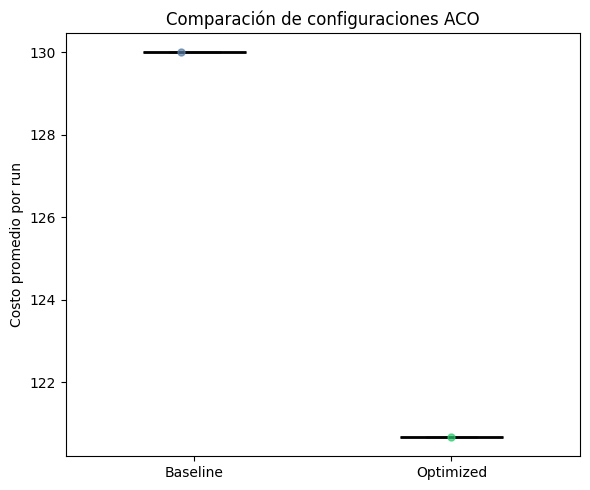

In [15]:
configs = {
    "Baseline":   (results_baseline,  "#5b7fa6"),                                                                                                                                     
    "Optimized":  (results_optimized, "#2ecc71"),
}                                                                                                                                                                                     
            
fig, ax = plt.subplots(figsize=(6, 5))                                                                                                                                                

for i, (label, (res, color)) in enumerate(configs.items()):                                                                                                                           
    runs = res["all_runs"]
    ax.boxplot(runs, positions=[i], widths=0.4, patch_artist=True,                                                                                                                    
                boxprops=dict(facecolor=color, alpha=0.6),                                                                                                                             
                medianprops=dict(color="black", linewidth=2),
                flierprops=dict(marker="o", markersize=4, alpha=0.4))                                                                                                                  
    ax.scatter(np.random.normal(i, 0.04, len(runs)), runs,                                                                                                                            
                color=color, alpha=0.7, s=25, zorder=5)                                                                                                                                
                                                                                                                                                                                    
ax.set_xticks([0, 1])                                                                                                                                                                 
ax.set_xticklabels(configs.keys())                                                                                                                                                    
ax.set_ylabel("Costo promedio por run")                                                                                                                                               
ax.set_title("Comparación de configuraciones ACO")
plt.tight_layout()                                                                                                                                                                    
plt.show()                  
                                                                                                                                                                                    
pct = (results_baseline["mean"] - results_optimized["mean"]) / results_baseline["mean"] * 100

FALTAN LOS TESTS!

In [16]:
from scipy import stats                                                                                                                                                               
                                                                                                                                                                                    
a = np.array(results_baseline["all_runs"])                                                                                                                                            
b = np.array(results_optimized["all_runs"])                                                                                                                                           
                                                                                                                                                                                    
t_stat, t_pval     = stats.ttest_ind(a, b)                                                                                                                                            
u_stat, u_pval     = stats.mannwhitneyu(a, b, alternative="two-sided")                                                                                                                
cohens_d           = (a.mean() - b.mean()) / np.sqrt((a.std()**2 + b.std()**2) / 2)                                                                                                   
                                                                                                                                                                                    
print(f"t-test:        t={t_stat:.3f},  p={t_pval:.4f}")                                                                                                                              
print(f"Mann-Whitney:  U={u_stat:.1f},  p={u_pval:.4f}")                                                                                                                              
print(f"Cohen's d:     {cohens_d:.3f}")

t-test:        t=nan,  p=nan
Mann-Whitney:  U=1.0,  p=1.0000
Cohen's d:     inf


/home/tmarmay/Documents/famaf/tesis/env/lib/python3.12/site-packages/scipy/stats/_stats_py.py:6316: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df
/tmp/ipykernel_136800/2797938750.py:8: RuntimeWarning: divide by zero encountered in scalar divide
  cohens_d           = (a.mean() - b.mean()) / np.sqrt((a.std()**2 + b.std()**2) / 2)
